# **CREATING CLASSIFICATION MODEL**

### **NAME: CALVIN D. MANAOR**

## **Pineapple Disease Risk Prediction Using Classification Model**

In this notebook, we will analyze a synthetic pineapple farm dataset and develop a classification model to predict pineapple disease risk based on different environmental and soil conditions. Using classification models, we aim to examine the relationships between temperature, humidity, soil moisture, rainfall, and soil pH to classify farm conditions into low and high disease risk categories.

The analysis is organized into the following sections:

1. Importing the Required Libraries
2. Reading the Dataset from GitHub
3. Exploratory Data Analysis (EDA)
4. Train-Test Split and Feature Scaling
5. Train and Compare Models
6. Interactive Predictions Using Best Model

Each section will help us understand the dataset, prepare the data, evaluate different classification algorithms, and identify the best performing model. This project will help the farmers know the optimal soil and climate conditions for pineapple cultivation to support agricultural monitoring and help farmers make informed decisions about pineapple crop management.

**Note:** The dataset used in this project is synthetically generated for educational purposes only. The predictions represent simulated disease risk classifications and are not actual agricultural diagnoses.

## **Context**

Pineapple is one of the important agricultural crops in the Philippines. However, pineapple crops can be affected by diseases and changing environmental conditions. Factors such as temperature, humidity, soil moisture, rainfall, and soil pH may affect crop health and growth.

We use dataset containing 600 randomly generated records representing different pineapple farm conditions in the Philippines. It includes five features: temperature, humidity, soil moisture, rainfall, and soil pH. These features are used to classify the farm conditions into two categories: Low Disease Risk (0) and High Disease Risk (1).

Through this we can help farmers become more aware of possible risks that can ruin crops and reduce fruit quality. It also help support better farm monitoring and decision making in Philippine agriculture.

### **Section 1. Importing the Required Libraries**

This section imports the necessary Python libraries and tools that will be used throughout the project. These libraries support dataset manipulation, numerical computations, data visualization, preprocessing, model training, and performance evaluation.

In [ ]:
# Core libraries for data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn tools for splitting, scaling, modeling, and evaluation
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

print("All libraries were imported successfully.")

All libraries were imported successfully.


### **Section 2. Reading the Dataset**

This section loads the generated pineapple disease risk dataset directly from the GitHub repository using its raw CSV link. The dataset contains 600 simulated pineapple farm observations, consisting of five numerical features and one response variable.

In [ ]:
# Load raw dataset directly from GitHub repository
data_url = "https://raw.githubusercontent.com/calvs30/classification-model/refs/heads/main/pineapple_disease_risk.csv"
df = pd.read_csv(data_url)

df.head()

,temperature_c,humidity_pct,soil_moisture_pct,rainfall_mm,soil_ph,disease_risk
0,25.99,54.29,71.87,5.55,4.54,1
1,35.21,60.32,16.84,8.41,4.14,0
2,31.71,54.74,16.66,7.77,4.14,0
3,29.58,49.88,39.27,29.52,3.78,0
4,22.50,51.63,51.65,44.57,4.24,1


### **Section 3. Exploratory Data Analysis (EDA)**

Exploratory Data Analysis (EDA) is performed to understand the dataset's structure, characteristics, and overall quality before applying machine learning algorithms. This section examines the dataset through numerical summaries and visualizations to identify patterns, distributions, possible data issues, and relationships between the features and the target variable.

#### 3.1 Check the Dataset Size

Checking the number of rows and columns using the **`df.shape`**

In [ ]:
# Check number of rows and columns
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")

Shape: 600 rows x 6 columns


#### 3.2 Check the Column Names and its Data types

Verifying the column names and its data types using the **`.info()`** shows column names, non-null counts, and data types. It ensures that the five input features and the response variable are correctly recognized and stored in appropriate formats for analysis and modeling.

In [ ]:
# Display dataset information
print("Dataset Overview:\n")
df.info()

Dataset Overview:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   temperature_c      600 non-null    float64
 1   humidity_pct       600 non-null    float64
 2   soil_moisture_pct  600 non-null    float64
 3   rainfall_mm        600 non-null    float64
 4   soil_ph            600 non-null    float64
 5   disease_risk       600 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 28.3 KB


#### 3.3 Check for Missing Values

The **`.isnull()`** is used to detect missing or null values within the dataset. Using it with **`.sum()`** gives the total count of missing values per column. Identifying missing values is important because incomplete data may affect the accuracy and reliability of the models.

In [ ]:
# Count missing values per column
missing_counts = df.isnull().sum()
print("Missing values per column:\n")
print(missing_counts)

Missing values per column:

temperature_c        0
humidity_pct         0
soil_moisture_pct    0
rainfall_mm          0
soil_ph              0
disease_risk         0
dtype: int64


#### 3.4 Check for Duplicate Rows

This identifies records that appear more than once in the dataset. Checking for duplicates helps maintain data quality and prevents repeated observations from unnecessarily influencing the analysis and model training.

In [ ]:
# Check for duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 0


#### 3.5 Summary Statistics

This presents the descriptive statistics of the numerical features, including the mean, standard deviation, minimum, maximum, and quartile values. These measurements provide an overview of the dataset's numerical characteristics and help identify unusual values or variations in the farm conditions.

In [ ]:
# Display descriptive statistics to check for outliers
print("\nDataset Summary Statistics:\n")
display(df.describe().round(2))


Dataset Summary Statistics:



,temperature_c,humidity_pct,soil_moisture_pct,rainfall_mm,soil_ph,disease_risk
count,600.00,600.00,600.00,600.00,600.00,600.00
mean,28.05,72.24,52.07,24.01,5.47,0.48
std,4.77,16.00,21.81,16.06,1.14,0.50
min,20.08,45.25,15.37,0.55,3.50,0.00
25%,23.87,57.80,32.58,11.71,4.44,0.00
50%,28.28,72.52,52.09,20.56,5.46,0.00
75%,32.22,86.13,69.90,32.33,6.49,1.00
max,36.00,99.89,89.96,93.44,7.50,1.00


#### 3.6 Feature Distributions

We used visualizations, such as histograms, to examine how the values of each numerical feature are distributed. It helps identify common value ranges, variations, and patterns in temperature, humidity, soil moisture, rainfall, and soil pH across the simulated pineapple farm observations.

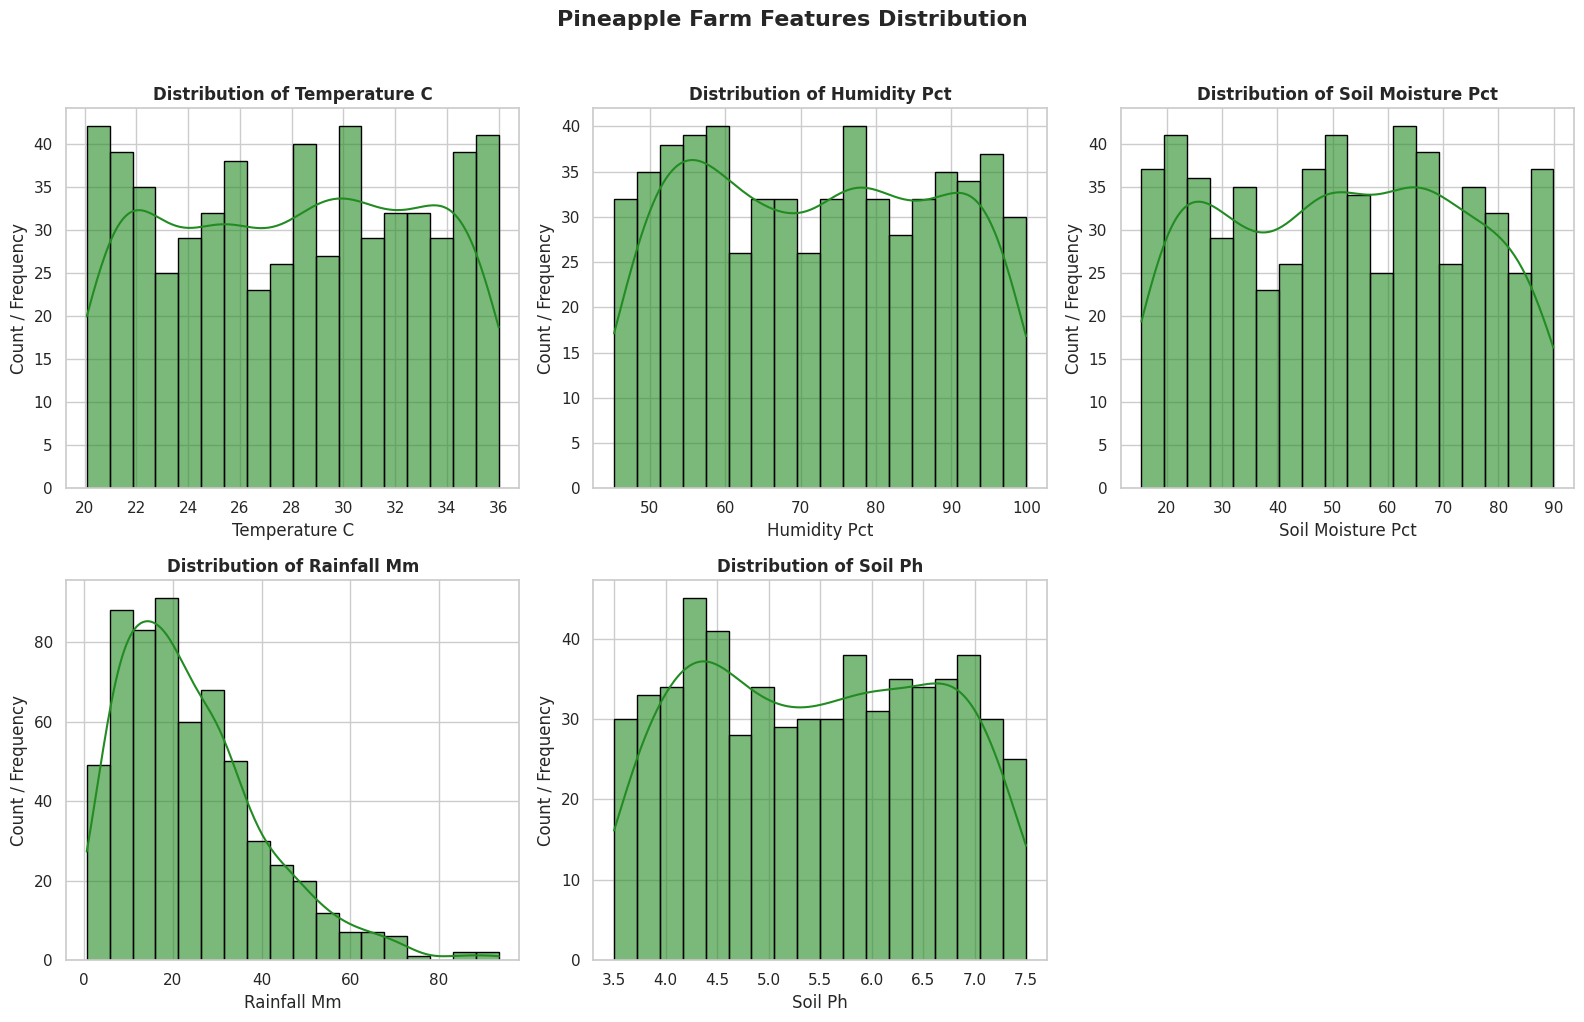

In [ ]:
# Plot histograms for all five numerical features
sns.set_theme(style="whitegrid")
features = ["temperature_c", "humidity_pct", "soil_moisture_pct", "rainfall_mm", "soil_ph"]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, bins=18, color='forestgreen', edgecolor='black', alpha=0.6, ax=axes[i])
    axes[i].set_title(f'Distribution of {col.replace("_", " ").title()}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col.replace('_', ' ').title(), fontsize=12)
    axes[i].set_ylabel('Count / Frequency', fontsize=12)

fig.delaxes(axes[5])

plt.suptitle("Pineapple Farm Features Distribution", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Interpretation:** The chart shows the spread of the five environmental and soil factors in the dataset. Temperature, humidity, soil moisture, and soil pH are spread across their ranges. Meanwhile, rainfall is mostly between 10 mm and 30 mm, with fewer records showing higher rainfall.

#### 3.7 Correlation Analysis

We used a correlation heatmap to examine the relationships between the numerical features and the disease risk response variable. It helps determine whether certain environmental and soil conditions have positive or negative associations with the predicted disease risk.

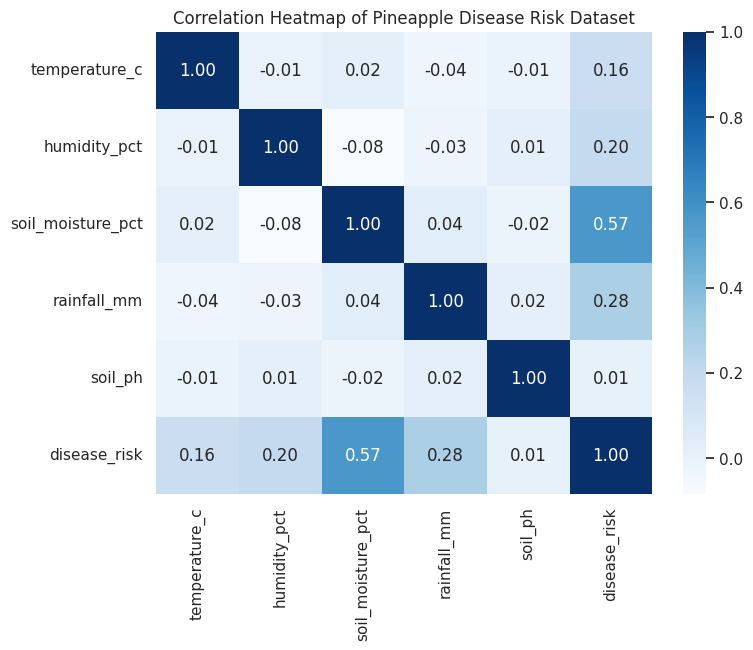

In [ ]:
# Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Heatmap of Pineapple Disease Risk Dataset')
plt.show()

**Interpretation:** Most features have weak relationships with each other. However, **`soil_moisture_pct`** has the strongest relationship with disease risk **(0.57)**, followed by **`rainfall_mm`** **(0.28)** and **`humidity_pct`** **(0.20)**. This shows that higher soil moisture and rainfall are linked to higher disease risk in the dataset.

#### 3.8 Check Class Imbalance

This examines the distribution of the two target classes: Low Disease Risk (0) and High Disease Risk (1). It determines whether the dataset has a relatively balanced number of observations or whether one class is significantly more represented than the other, which could affect the performance of the classification models

Class Distribution Summary Table:


,Count,Percentage (%)
"Disease Risk Status (0 = Healthy, 1 = High Risk)",,
0,314,52.33
1,286,47.67


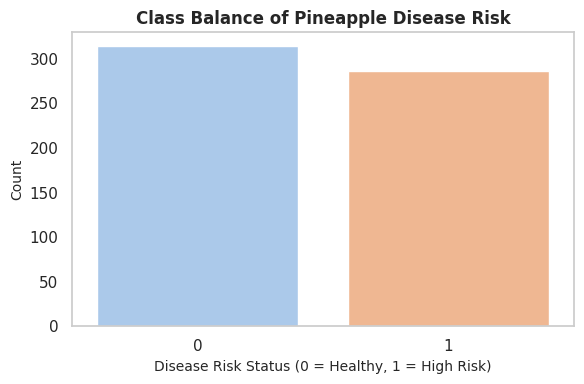

In [ ]:
# Check class distribution of target variable (disease_risk)
counts = df['disease_risk'].value_counts()
percentages = df['disease_risk'].value_counts(normalize=True) * 100

df_class_summary = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': percentages.round(2)
})

df_class_summary.index.name = 'Disease Risk Status (0 = Healthy, 1 = High Risk)'
print("Class Distribution Summary Table:")
display(df_class_summary)

plt.figure(figsize=(6, 4))
sns.countplot(x='disease_risk', data=df, hue='disease_risk', palette='pastel', legend=False)
plt.title('Class Balance of Pineapple Disease Risk', fontsize=12, fontweight='bold')
plt.xlabel('Disease Risk Status (0 = Healthy, 1 = High Risk)', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.tight_layout()
plt.grid(False)
plt.show()

**Interpretation:** The class distribution table and bar chart show the number of samples in each disease risk category. Out of 600 samples, 314 (52.33%) are classified as Low Risk, while 286 (47.67%) are classified as High Risk. This shows that the dataset is balanced, which is helpful for training the classification models.

### **Section 4. Train-Test Split and Feature Scaling**

This section prepares the dataset for machine learning by separating the input features from the response variable and dividing the observations into training and testing sets. It also introduces feature scaling to ensure that numerical variables with different measurement ranges are standardized. These preparation steps help establish a consistent process for training and evaluating the classification algorithms.

#### 4.1 Splitting the Data

We divide the dataset into two separate groups: a training set and a testing set. The training set is used to develop the classification models, while the testing set is reserved for evaluating their ability to predict previously unseen observations. An 80:20 ratio is applied, with 80% allocated for training and 20% for testing.

In [ ]:
# Separate features (X) and response variable (y)
X = df.drop(columns=['disease_risk'])
y = df['disease_risk']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training Feature Set: {X_train.shape[0]} rows, {X_train.shape[1]} columns/features: {X_train.shape}")
print(f"Test Feature Set    : {X_test.shape[0]} rows, {X_test.shape[1]} columns/features: {X_test.shape}")
print(f"Training Target Set : {y_train.shape[0]} rows: {y_train.shape}")
print(f"Testing Target Set  : {y_test.shape[0]} rows: {y_test.shape}")
print(f"\nTrain positive rate : {y_train.mean():.3f}")
print(f"Test positive rate  :  {y_test.mean():.3f}")

Training Feature Set: 480 rows, 5 columns/features: (480, 5)
Test Feature Set    : 120 rows, 5 columns/features: (120, 5)
Training Target Set : 480 rows: (480,)
Testing Target Set  : 120 rows: (120,)

Train positive rate : 0.477
Test positive rate  :  0.475


#### 4.2 Show Samples from Training and Test Sets

We display sample records from both the training and testing sets. It provides a closer look at how the observations are distributed after splitting and verifies that the input features and response variable have been separated correctly.

In [ ]:
# Display samples of both sets
print("Training Set Sample:")
display(X_train.head(3))

print("\n\nTesting Set Sample:")
display(X_test.head(3))

Training Set Sample:


,temperature_c,humidity_pct,soil_moisture_pct,rainfall_mm,soil_ph
558,32.08,92.95,23.23,8.89,5.88
196,31.62,96.27,47.32,39.23,4.58
383,34.04,49.13,52.26,6.65,4.08




Testing Set Sample:


,temperature_c,humidity_pct,soil_moisture_pct,rainfall_mm,soil_ph
496,29.34,57.13,16.94,4.58,4.14
482,27.27,67.97,63.07,7.45,4.18
154,35.77,52.66,51.50,45.40,6.51


#### 4.3 Scaling the Features

**`StandardScaler`** was applied to standardize the numerical input features. It transforms the feature values based on their mean and standard deviation, allowing them to have a comparable scale.

In [ ]:
# Create the scaler and fit it on the TRAINING data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Mean of each scaled training feature (should be close to 0):")
print(np.round(X_train_scaled.mean(axis=0), 3))
print("\nStandard deviation of each scaled training feature (should be close to 1):")
print(np.round(X_train_scaled.std(axis=0), 3))

Mean of each scaled training feature (should be close to 0):
[ 0. -0. -0. -0.  0.]

Standard deviation of each scaled training feature (should be close to 1):
[1. 1. 1. 1. 1.]


### **Section 5. Train and Compare Models**

This section focuses on developing and evaluating five different classification algorithms to determine which performs best in predicting pineapple disease risk. Each algorithm is trained and used **`GridSearchCV`** to identify suitable hyperparameters. Their performance is then compared using evaluation metrics such as accuracy, precision, recall, and F1 score to identify the most suitable model for the classification task.

#### **Classification Models and Hyperparameters**

We will use five classification algorithms to predict pineapple disease risk: Logistic Regression, Random Forest, Support Vector Machine (SVM), K-Nearest Neighbors (KNN), and Decision Tree. Each model has different hyperparameters that control how it learns and makes predictions. These hyperparameters will be tested to find the best settings for each model.

| Classification Model | Hyperparameter | Purpose |
|---|---|---|
| **Logistic Regression** | `C` | Controls the strength of regularization. A smaller value applies stronger regularization. |
| **Random Forest** | `n_estimators` | Determines the number of decision trees used in the model. |
| | `max_depth` | Sets the maximum depth of each decision tree. |
| **Support Vector Machine (SVM)** | `C` | Controls the balance between correct classification and classification errors. |
| | `kernel` | Determines the type of function used to separate the data into different classes. |
| **K-Nearest Neighbors (KNN)** | `n_neighbors` | Determines how many nearby data points are considered when making a prediction. |
| | `weights` | Determines whether all neighbors have equal importance or closer neighbors have more influence. |
| **Decision Tree** | `max_depth` | Sets the maximum depth of the decision tree. |
| | `min_samples_split` | Sets the minimum number of samples required to split a node into smaller branches. |


#### 5.1 Model Training and Evaluation

We train five classification algorithms: Logistic Regression, K-Nearest Neighbors, Support Vector Machine, Random Forest, and Decision Tree **`GridSearchCV`** is used to search for the best hyperparameter of each model. Each model is then evaluated using the evaluation metrics.

In [ ]:
# Define 5 classification models and their hyperparameters
models_params = {
    'Logistic Regression': {
        'model': LogisticRegression(random_state=42),
        'params': {'C': [0.1, 1.0, 10.0]}},
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {'n_estimators': [50, 100], 'max_depth': [3, 5, None]}},
    'SVM': {
        'model': SVC(random_state=42, probability=True),
        'params': {'C': [0.1, 1.0], 'kernel': ['linear', 'rbf']}},
    'KNN': {
        'model': KNeighborsClassifier(),
        'params': {'n_neighbors': [3, 5, 7], 'weights': ['uniform', 'distance']}},
    'Decision Tree': {
        'model': DecisionTreeClassifier(random_state=42),
        'params': {'max_depth': [3, 5, 10], 'min_samples_split': [2, 5, 10]}}
}

evaluation_results = []

for name, mp in models_params.items():
    # Perform GridSearch
    clf = GridSearchCV(mp['model'], mp['params'], cv=5, scoring='accuracy')
    clf.fit(X_train_scaled, y_train)

    # Predict on test set
    y_pred = clf.predict(X_test_scaled)

    # Store metrics and best model
    evaluation_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'Best Estimator': clf.best_estimator_,
        'Best Parameters': clf.best_params_
    })

print("All 5 models trained and evaluated successfully!")

All 5 models trained and evaluated successfully!


#### 5.2 Comparison Table

This presents a comparison of the five trained classification algorithms using a performance evaluation table. The table includes accuracy, precision, recall, and F1 score to provide a clearer understanding of how well each model performs in classifying low-risk and high-risk observations.

In [ ]:
# Display top models
df_results = pd.DataFrame(evaluation_results)
df_sorted = df_results.sort_values(by=['Accuracy', 'F1-Score'], ascending=False).reset_index(drop=True)

print("Model Comparison Leaderboard:")
display(df_sorted[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score']])

Model Comparison Leaderboard:


,Model,Accuracy,Precision,Recall,F1-Score
0,SVM,0.833333,0.833982,0.833333,0.833426
1,Logistic Regression,0.825000,0.826250,0.825000,0.825109
2,KNN,0.825000,0.824944,0.825000,0.824915
3,Random Forest,0.816667,0.816713,0.816667,0.816462
4,Decision Tree,0.733333,0.735786,0.733333,0.731231


The comparison table shows that the Support Vector Machine (SVM) performed best with an accuracy of 83.33%, followed closely by Logistic Regression and KNN at 82.50%. Random Forest achieved 81.67%, while the Decision Tree scored the lowest at 73.33%.

#### 5.3 Accuracy Bar Chart

We visualized the test accuracy scores of the five classification algorithms using a bar chart. It provides an easy to understand comparison of their predictive performance and helps identify which algorithms achieved higher accuracy on the testing dataset.

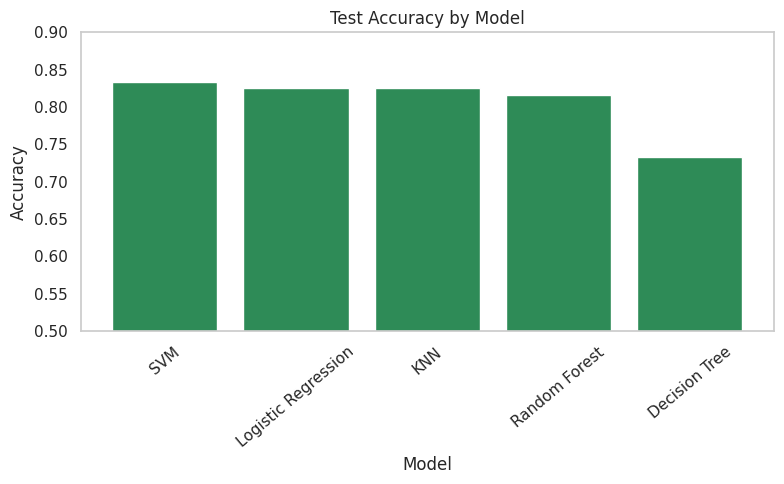

In [ ]:
# Display bar chart of accuracy for each model
plt.figure(figsize=(8, 5))
plt.bar(df_sorted["Model"], df_sorted["Accuracy"], color="seagreen")
plt.ylim(0.5, 0.9)
plt.title("Test Accuracy by Model")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=40)
plt.tight_layout()
plt.grid(False)
plt.show()

#### 5.4 Select the Best Model

We identify the classification algorithm with the highest test accuracy score among the five evaluated models. It also displays the best hyperparameters selected through **`GridSearchCV`**.

In [ ]:
# Show the best performing model
best_row = df_sorted.iloc[0]

print(f"Best Algorithm      : {best_row['Model']}")
print(f"Test Accuracy Score : {best_row['Accuracy']:.4f}")
print(f"F1-Score            : {best_row['F1-Score']:.4f}")
print("\nBest Hyperparameters:")
for param, val in best_row['Best Parameters'].items():
    print(f" - {param}: {val}")

Best Algorithm      : SVM
Test Accuracy Score : 0.8333
F1-Score            : 0.8334

Best Hyperparameters:
 - C: 0.1
 - kernel: linear


#### 5.5 Confusion Matrix of the Best Model

Confusion matrix of the selected classification algorithm was created to examine its prediction results in greater detail. It shows the number of correctly and incorrectly classified observations for both low disease risk and high disease risk, helping assess the model's ability to distinguish between the two classes.

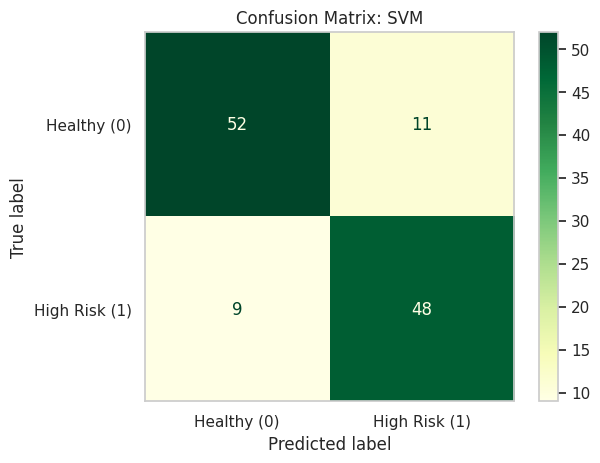

In [ ]:
# Display confusion matrix
best_pred = best_row['Best Estimator'].predict(X_test_scaled)
cm = confusion_matrix(y_test, best_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Healthy (0)', 'High Risk (1)'])
disp.plot( cmap='YlGn')
plt.title(f"Confusion Matrix: {best_row['Model']}")
plt.grid(False)
plt.show()

### **Section 6. Interactive Predictions Using the Best Model**

 Users can now test the best classification model by entering five numerical values representing pineapple farm conditions. The model uses these inputs to predict whether the farm has a low or high disease risk. This demonstrates how the trained model can be used to make predictions based on different farm conditions.

In [ ]:
# Predict using the best model
best_model = best_row['Best Estimator']

print("---- Pineapple Disease Risk Predictor ----")
print("Please enter the 5 required values:")

def get_valid_input(prompt, min_val, max_val):
    while True:
        try:
            val = float(input(prompt))
            if min_val <= val <= max_val:
                return val
            else:
                print(f"Value must be between {min_val} and {max_val}. Try again.")
        except ValueError:
            print("Invalid input. Please enter a valid number.")

temp_in = get_valid_input("Enter Temperature (20.0 - 36.0 °C): ", 20.0, 36.0)
humidity_in = get_valid_input("Enter Humidity (45.0 - 100.0 %): ", 45.0, 100.0)
moisture_in = get_valid_input("Enter Soil Moisture (15.0 - 90.0 %): ", 15.0, 90.0)
rainfall_in = get_valid_input("Enter Rainfall (0.5 - 95.0 mm): ", 0.5, 95.0)
ph_in = get_valid_input("Enter Soil pH (3.5 - 7.5): ", 3.5, 7.5)

# Build input dataframe
input_data = pd.DataFrame([[temp_in, humidity_in, moisture_in, rainfall_in, ph_in]],
                          columns=['temperature_c', 'humidity_pct', 'soil_moisture_pct', 'rainfall_mm', 'soil_ph'])

input_data_scaled = scaler.transform(input_data)

# Predict using the scaled input
prediction = best_model.predict(input_data_scaled)[0]
probability = best_model.predict_proba(input_data_scaled)[0]

print("\n" + "="*50)
print("PREDICTION RESULT:")
if prediction == 1:
    print("HIGH RISK OF PINEAPPLE DISEASE DETECTED (Class 1)")
    print(f"Confidence: {probability[1]*100:.2f}%")
else:
    print("PINEAPPLE CROP IS HEALTHY / LOW RISK (Class 0)")
    print(f"Confidence: {probability[0]*100:.2f}%")
print("="*50)

---- Pineapple Disease Risk Predictor ----
Please enter the 5 required values:
Enter Temperature (20.0 - 36.0 °C): 33.2
Enter Humidity (45.0 - 100.0 %): 74
Enter Soil Moisture (15.0 - 90.0 %): 62
Enter Rainfall (0.5 - 95.0 mm): 52.3
Enter Soil pH (3.5 - 7.5): 5.4

PREDICTION RESULT:
HIGH RISK OF PINEAPPLE DISEASE DETECTED (Class 1)
Confidence: 97.48%


### **Summary and Conclusion**

- This project focuses on predicting pineapple disease risk that can reduced its quality using a classification model.
- The dataset contains five features: temperature, humidity, soil moisture, rainfall, and soil pH.
- EDA was performed to understand the data and identify relationships between the features.
- Different classification models were trained and compared, and Support Vector Machine (SVM) achieved the best performance.
- The results show that soil moisture, rainfall, and humidity are related to disease risk in the dataset.